In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\medisa\Downloads\netflix_titles.csv\netflix_titles.csv",index_col="show_id")

In [3]:
df

,type,title,director,country,date_added,release_year,rating,duration,listed_in
show_id,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
s8,Movie,Sankofa,Haile Gerima,"United States, Ghana, Burkina Faso, United Kin...",9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
s13,Movie,Je Suis Karl,Christian Schwochow,"Germany, Czech Republic",9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
...,...,...,...,...,...,...,...,...,...
s8802,Movie,Zinzana,Majid Al Ansari,"United Arab Emirates, Jordan",3/9/2016,2015,TV-MA,96 min,"Dramas, International Movies, Thrillers"
s8803,Movie,Zodiac,David Fincher,United States,11/20/2019,2007,R,158 min,"Cult Movies, Dramas, Thrillers"
s8805,Movie,Zombieland,Ruben Fleischer,United States,11/1/2019,2009,R,88 min,"Comedies, Horror Movies"


In [4]:
df.drop_duplicates()

,type,title,director,country,date_added,release_year,rating,duration,listed_in
show_id,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
s8,Movie,Sankofa,Haile Gerima,"United States, Ghana, Burkina Faso, United Kin...",9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
s13,Movie,Je Suis Karl,Christian Schwochow,"Germany, Czech Republic",9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
...,...,...,...,...,...,...,...,...,...
s8802,Movie,Zinzana,Majid Al Ansari,"United Arab Emirates, Jordan",3/9/2016,2015,TV-MA,96 min,"Dramas, International Movies, Thrillers"
s8803,Movie,Zodiac,David Fincher,United States,11/20/2019,2007,R,158 min,"Cult Movies, Dramas, Thrillers"
s8805,Movie,Zombieland,Ruben Fleischer,United States,11/1/2019,2009,R,88 min,"Comedies, Horror Movies"


In [5]:
df = df.rename(columns={"listed_in": "genre"})

In [6]:
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

In [7]:
df['year_added'] = df['date_added'].dt.year

In [8]:
df.isnull().sum()
df['country'] = df['country'].fillna('Unknown')

How many movies and TV shows are on Netflix?

In [9]:
type_count = df['type'].value_counts()

print(type_count)

type
Movie      5558
TV Show     189
Name: count, dtype: int64


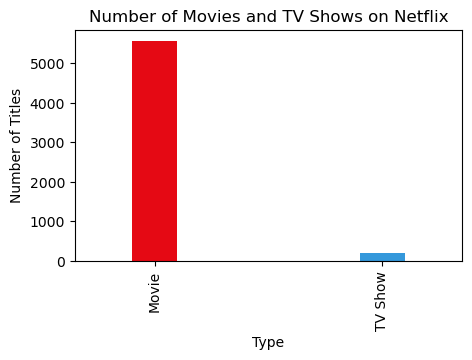

In [63]:
type_count.plot(kind="bar",color=["#E50914","#3498DB"],figsize=(5, 3),width=0.2)

plt.title('Number of Movies and TV Shows on Netflix')
plt.xlabel('Type')
plt.ylabel('Number of Titles')
plt.show()

Which genres are most common on Netflix?

In [11]:
genres = df['genre'].str.split(', ').explode()

genres.value_counts().head(10)

genre
International Movies        2505
Dramas                      2297
Comedies                    1555
Action & Adventure           809
Documentaries                751
Independent Movies           740
Romantic Movies              580
Thrillers                    547
Children & Family Movies     513
Horror Movies                338
Name: count, dtype: int64

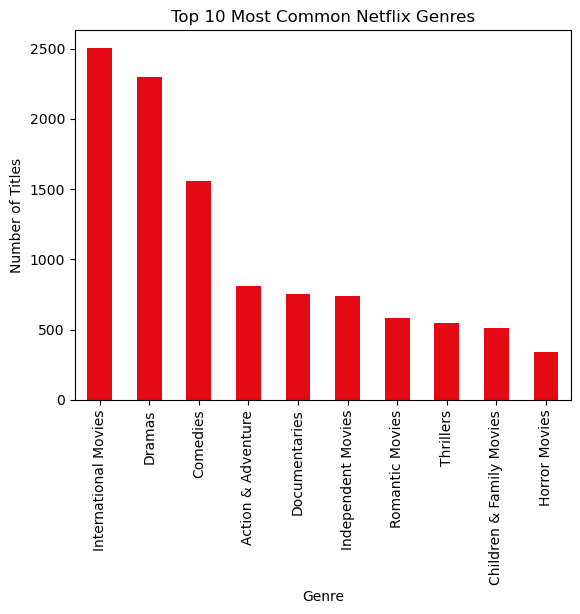

In [64]:
genres.value_counts().head(10).plot(kind="bar",color="#E50914")

plt.title('Top 10 Most Common Netflix Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.show()

Which countries produce the most Netflix content?

In [13]:
countries = df['country'].str.split(', ').explode()

countries.value_counts().head(10)

country
United States     2746
India              961
United Kingdom     537
Canada             317
France             311
Spain              181
Germany            180
Japan              130
Mexico             115
China              114
Name: count, dtype: int64

What are the most common content ratings?

In [14]:
rating_count=df['rating'].value_counts()
print(rating_count)

rating
TV-MA       1979
TV-14       1330
R            784
TV-PG        505
PG-13        481
PG           281
TV-G         103
TV-Y7         81
TV-Y          79
NR            75
G             41
TV-Y7-FV       3
UR             3
NC-17          2
Name: count, dtype: int64


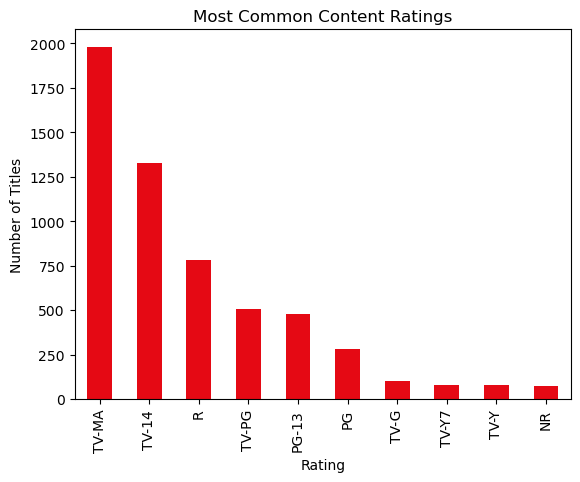

In [65]:
rating_count.head(10).plot(kind="bar",color="#E50914")

plt.title('Most Common Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.show()

What is the typical duration of Netflix movies?

In [16]:
movies = df[df['type'] == 'Movie'].copy()

In [17]:
movies['duration'].head()

show_id
s1      90 min
s8     125 min
s10    104 min
s13    127 min
s25    166 min
Name: duration, dtype: object

In [18]:
movies['duration'] = movies['duration'].str.replace(' min', '')

In [19]:
movies['duration']=movies['duration']=pd.to_numeric(movies['duration'])

In [20]:
print("Average:", movies['duration'].mean().round(2))
print("Median:", movies['duration'].median())
print("Max:", movies['duration'].max())
print("Min", movies['duration'].min())

Average: 101.18
Median: 99.0
Max: 253
Min 3


How has the amount of Netflix content changed over the years?

In [21]:
content_by_years=df['release_year'].value_counts().sort_index(ascending=False)
print(content_by_years)

release_year
2021    185
2020    488
2019    571
2018    707
2017    735
       ... 
1946      2
1945      3
1944      3
1943      3
1942      2
Name: count, Length: 73, dtype: int64


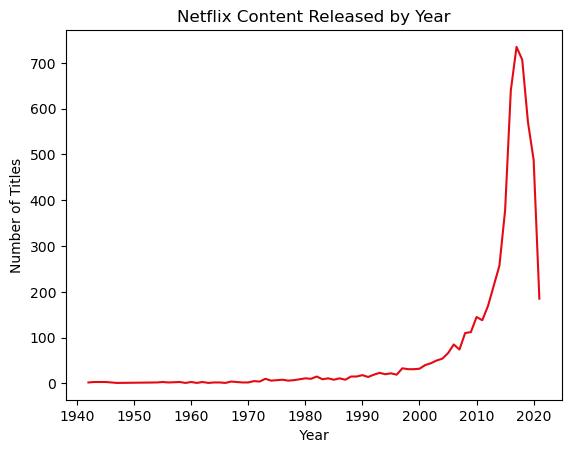

In [66]:
content_by_years.plot(kind="line",color="#E50914")

plt.title('Netflix Content Released by Year')
plt.xlabel(' Year ')
plt.ylabel('Number of Titles')
plt.show()

How has the proportion of Movies and TV Shows changed over time?

In [23]:
content=df.groupby(['release_year','type']).size().unstack()
print(content.head(10))

type          Movie  TV Show
release_year                
1942            2.0      NaN
1943            3.0      NaN
1944            3.0      NaN
1945            3.0      NaN
1946            1.0      1.0
1947            1.0      NaN
1954            2.0      NaN
1955            3.0      NaN
1956            2.0      NaN
1958            3.0      NaN


In [24]:
proportion = content.div(content.sum(axis=1), axis=0) * 100

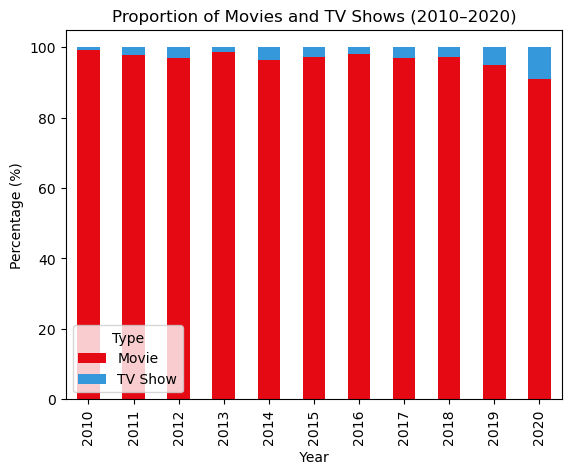

In [67]:
proportion.loc[2010:2020].plot(kind='bar',stacked=True,color=["#E50914","#3498DB"])


plt.title('Proportion of Movies and TV Shows (2010–2020)')
plt.xlabel(' Year ')
plt.ylabel('Percentage (%)')
plt.legend(title='Type')
plt.show()

Which directors have the most titles on Netflix?  

In [26]:
directors = df['director'].dropna()

In [27]:
directors=directors.str.split(' , ').explode()

In [28]:
director_count=directors.value_counts().sort_values(ascending=False)
print(director_count.head(10))

director
Raúl Campos, Jan Suter    18
Marcus Raboy              15
Jay Karas                 14
Cathy Garcia-Molina       13
Jay Chapman               12
Youssef Chahine           12
Martin Scorsese           12
Steven Spielberg          11
Don Michael Paul          10
David Dhawan               9
Name: count, dtype: int64


Which genres are most popular in different countries?

In [29]:
country_genre=df.dropna(subset=['country','genre'])

In [30]:
country_genre['country']=country_genre['country'].str.split(', ')
country_genre = country_genre.explode('country')

In [31]:
country_genre['genre']=country_genre['genre'].str.split(', ')
country_genre = country_genre.explode('genre')

In [32]:
genre_by_country=(
    country_genre
    .groupby(['country','genre'])
    .size()
)

In [33]:
top_genre_by_country=(
    genre_by_country
    .groupby(level=0)
    .idxmax()
)


In [34]:
print(top_genre_by_country)

country
                                          (, Dramas)
Afghanistan             (Afghanistan, Documentaries)
Albania                            (Albania, Dramas)
Algeria                            (Algeria, Dramas)
Angola                  (Angola, Action & Adventure)
                                ...                 
Vatican City           (Vatican City, Documentaries)
Venezuela                 (Venezuela, Documentaries)
Vietnam              (Vietnam, International Movies)
West Germany    (West Germany, International Movies)
Zimbabwe            (Zimbabwe, International Movies)
Length: 122, dtype: object


Only  the top 10 countries

In [35]:
top_countries = country_genre['country'].value_counts().head(10).index

In [36]:
result = country_genre[
    country_genre['country'].isin(top_countries)
]

In [37]:
result = (
    result.groupby(['country', 'genre'])
    .size()
    .groupby(level=0)
    .idxmax()
)

print(result)

country
Canada                         (Canada, Comedies)
China               (China, International Movies)
France             (France, International Movies)
Germany           (Germany, International Movies)
India               (India, International Movies)
Japan               (Japan, International Movies)
Mexico             (Mexico, International Movies)
Spain               (Spain, International Movies)
United Kingdom           (United Kingdom, Dramas)
United States             (United States, Dramas)
dtype: object


Which years had the most content added to Netflix?  

In [38]:
content_by_year=df['year_added'].value_counts()
print(content_by_year)

year_added
2019.0    1351
2020.0    1256
2018.0    1173
2017.0     826
2021.0     797
2016.0     238
2015.0      56
2014.0      18
2011.0      13
2013.0       7
2012.0       3
2009.0       2
2008.0       1
2010.0       1
Name: count, dtype: int64


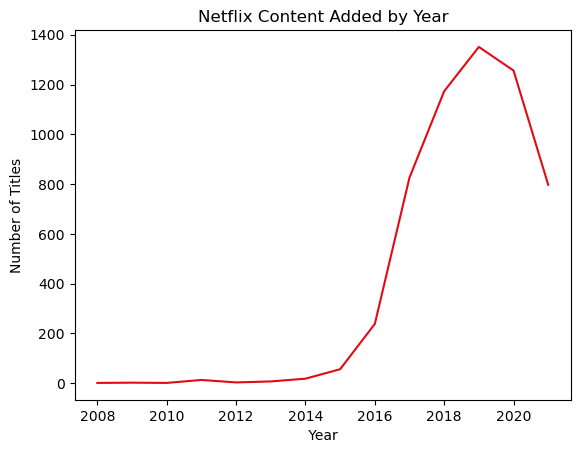

In [68]:
content_added = df['year_added'].value_counts().sort_index()

content_added.plot(kind='line',color="#E50914")

plt.title('Netflix Content Added by Year')
plt.xlabel(' Year ')
plt.ylabel('Number of Titles')
plt.show()

Do Movies and TV Shows have different rating distributions?  

In [40]:
rating_distribution=pd.crosstab(df['rating'],df['type'])
print(rating_distribution)

type      Movie  TV Show
rating                  
G            41        0
NC-17         2        0
NR           75        0
PG          281        0
PG-13       481        0
R           784        0
TV-14      1282       48
TV-G         99        4
TV-MA      1876      103
TV-PG       485       20
TV-Y         73        6
TV-Y7        73        8
TV-Y7-FV      3        0
UR            3        0


Has Netflix's content library grown over time?

In [41]:
df

,type,title,director,country,date_added,release_year,rating,duration,genre,year_added
show_id,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021.0
s8,Movie,Sankofa,Haile Gerima,"United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021.0
s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,2021-09-24,2021,TV-14,9 Seasons,"British TV Shows, Reality TV",2021.0
s10,Movie,The Starling,Theodore Melfi,United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas",2021.0
s13,Movie,Je Suis Karl,Christian Schwochow,"Germany, Czech Republic",2021-09-23,2021,TV-MA,127 min,"Dramas, International Movies",2021.0
...,...,...,...,...,...,...,...,...,...,...
s8802,Movie,Zinzana,Majid Al Ansari,"United Arab Emirates, Jordan",2016-03-09,2015,TV-MA,96 min,"Dramas, International Movies, Thrillers",2016.0
s8803,Movie,Zodiac,David Fincher,United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers",2019.0
s8805,Movie,Zombieland,Ruben Fleischer,United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",2019.0


In [42]:
increased_by_years=df['year_added'].value_counts()
print(increased_by_years)

year_added
2019.0    1351
2020.0    1256
2018.0    1173
2017.0     826
2021.0     797
2016.0     238
2015.0      56
2014.0      18
2011.0      13
2013.0       7
2012.0       3
2009.0       2
2008.0       1
2010.0       1
Name: count, dtype: int64


How does the United States compare with other countries in Netflix production?  

In [43]:
countries=df['country'].dropna().str.split(' , ').explode()

In [44]:
cunt_countries=countries.value_counts()
print(cunt_countries.head(10))

country
United States     2045
India              890
United Kingdom     212
Canada             119
Spain              106
Nigeria             90
Egypt               90
Japan               85
France              81
Turkey              79
Name: count, dtype: int64


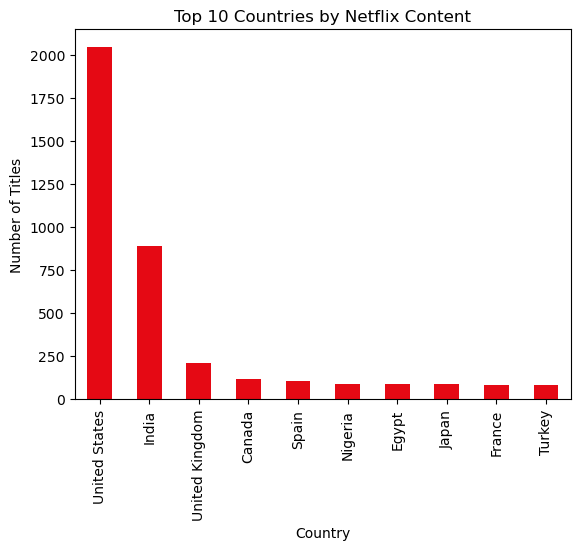

In [69]:
cunt_countries.head(10).plot(kind="bar",color="#E50914")

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.show()

Which genres have become more common over time?  

In [46]:
genre_data=df[['year_added','genre']].dropna().copy()


genre_data['genre']=genre_data['genre'].str.split(' , ')
genre_data=genre_data.explode('genre')

In [47]:
genre_by_year=genre_data.groupby(['year_added','genre']).size().unstack(fill_value=0)


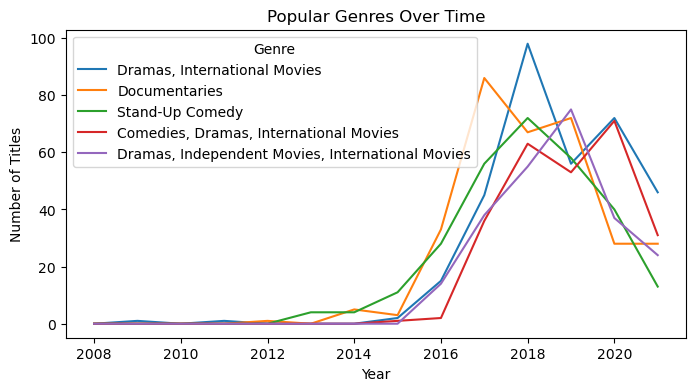

In [48]:
top_genres=genre_data['genre'].value_counts().head(5).index

genre_by_year[top_genres].plot(
    kind='line',
    figsize=(8, 4)
)

plt.title('Popular Genres Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend(title='Genre')
plt.show()

Has the average movie duration changed over the years?  

In [49]:
movies = df[df['type'] == 'Movie'].copy()

In [50]:
movies['duration'] = movies['duration'].str.replace(' min', '')
movies['duration'] = pd.to_numeric(movies['duration'])

In [51]:
avg_duration = movies.groupby('release_year')['duration'].mean()

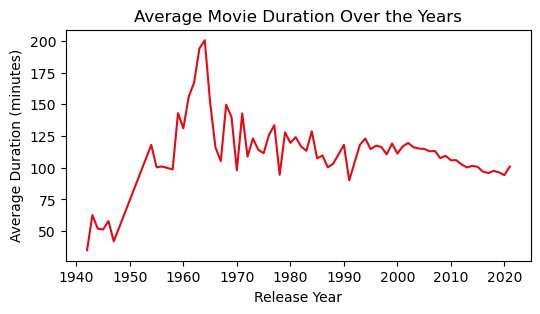

In [70]:
avg_duration.plot(
    kind='line',
    figsize=(6, 3),
    color="#E50914"
)

plt.title('Average Movie Duration Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (minutes)')
plt.show()

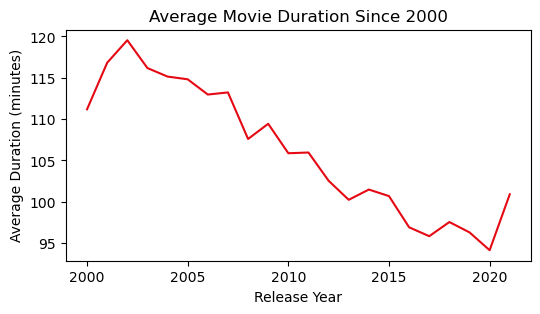

In [71]:
avg_duration.loc[2000:].plot(
    kind='line',
    figsize=(6, 3),
    color="#E50914"
)

plt.title('Average Movie Duration Since 2000')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (minutes)')
plt.show()

Does Netflix focus more on Movies or TV Shows?

In [54]:
count_type=df['type'].value_counts()
print(count_type)

type
Movie      5558
TV Show     189
Name: count, dtype: int64


In [55]:
percentage_type=df['type'].value_counts(normalize=True)*100
print(percentage_type.round(2))

type
Movie      96.71
TV Show     3.29
Name: proportion, dtype: float64


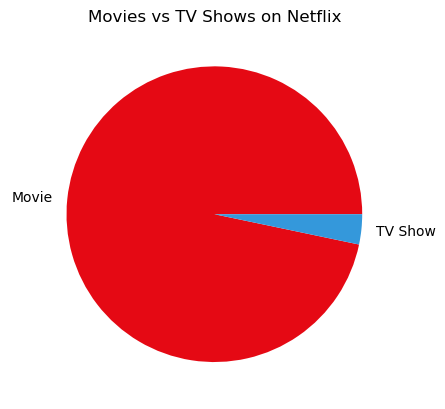

In [72]:
type_count.plot(kind="pie",colors=["#E50914","#3498DB"])

plt.title('Movies vs TV Shows on Netflix')
plt.ylabel(' ')
plt.show()

How important is international content to Netflix?  

In [57]:
df['content_origin'] = df['country'].apply(
    lambda x: 'US' if pd.notna(x) and 'United States' in x
    else 'International'
)

In [58]:
origin_count = df['content_origin'].value_counts()

print(origin_count)

content_origin
International    3000
US               2747
Name: count, dtype: int64


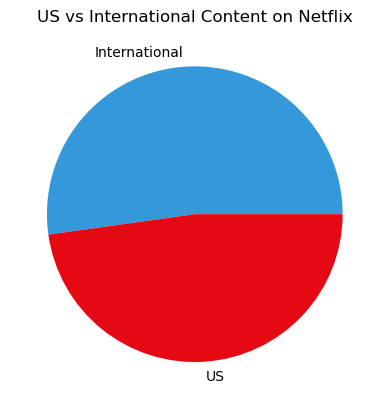

In [73]:
origin_count.plot(kind="pie",colors=["#3498DB","#E50914"])

plt.title('US vs International Content on Netflix')
plt.ylabel('')
plt.show()